# 03 - Build causal sensor features

Run notebook 02 first (or `uv run pm-train`). Each sensor gains a local linear slope over the configured history window. Earlier cycles and other engines cannot use future values.

Outputs: training and test feature/label CSVs under `data/processed/`. IDs remain in those files for splitting and alignment, but are excluded from classical estimator inputs.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
from predictive_maintenance.features.engineering import engineer_dataset

for split in ("train", "test"):
    source = INTERIM_DATA_DIR / f"{split}_preprocessed.csv"
    if not source.exists():
        raise FileNotFoundError("Run notebook 02 or `uv run pm-train` before feature engineering.")
    engineer_dataset(source, PROCESSED_DATA_DIR / f"{split}_features.csv",
                     PROCESSED_DATA_DIR / f"{split}_labels.csv")

train_features = pd.read_csv(PROCESSED_DATA_DIR / "train_features.csv")
test_features = pd.read_csv(PROCESSED_DATA_DIR / "test_features.csv")
train_labels = pd.read_csv(PROCESSED_DATA_DIR / "train_labels.csv")
test_labels = pd.read_csv(PROCESSED_DATA_DIR / "test_labels.csv")
assert train_features.columns.tolist() == test_features.columns.tolist()
for features, labels in ((train_features, train_labels), (test_features, test_labels)):
    pd.testing.assert_frame_equal(features[["unit", "cycle"]], labels[["unit", "cycle"]])
    assert "RUL" not in features
    assert np.isfinite(features.to_numpy()).all()
display(train_features.head())


,unit,cycle,os_1,os_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,sensor_2_slope,sensor_3_slope,sensor_4_slope,sensor_6_slope,sensor_7_slope,sensor_8_slope,sensor_9_slope,sensor_11_slope,sensor_12_slope,sensor_13_slope,sensor_14_slope,sensor_15_slope,sensor_17_slope,sensor_20_slope,sensor_21_slope
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,0.000,0.000,0.000,0.000000e+00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00000,0.000000e+00,0.000,0.00000
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,0.330,2.120,2.540,-3.256040e-15,-0.610,-0.020,-2.120,0.020,0.620,0.050,-7.130,0.01230,-8.637964e-14,-0.060,0.00460
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,0.265,-0.855,1.800,2.969972e-16,-0.050,0.010,3.375,-0.100,0.380,0.005,-2.695,-0.00085,-1.000000e+00,-0.055,-0.03740
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,0.179,-2.456,0.487,5.999522e-16,0.078,0.019,1.874,-0.124,0.374,0.014,-1.263,-0.01679,-2.000000e-01,-0.059,-0.02147
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,0.130,-2.273,0.997,-2.338424e-15,-0.002,0.007,2.333,-0.074,0.164,0.005,-0.730,-0.00438,2.000000e-01,-0.044,-0.00789


## Inspect the feature schema


In [4]:
sensor_columns = [column for column in train_features if column.startswith("sensor_") and not column.endswith("_slope")]
model_columns = [column for column in train_features if column not in ("unit", "cycle")]
display(pd.DataFrame({"feature": model_columns,
                      "kind": ["trend" if name.endswith("_slope") else "raw" for name in model_columns]}))
print(f"{len(model_columns)} model inputs; causal trend window = {TREND_WINDOW} cycles")


,feature,kind
0,os_1,raw
1,os_2,raw
2,sensor_2,raw
3,sensor_3,raw
4,sensor_4,raw
5,sensor_6,raw
6,sensor_7,raw
7,sensor_8,raw
8,sensor_9,raw
9,sensor_11,raw


32 model inputs; causal trend window = 10 cycles


## Compare a sensor's level and trend


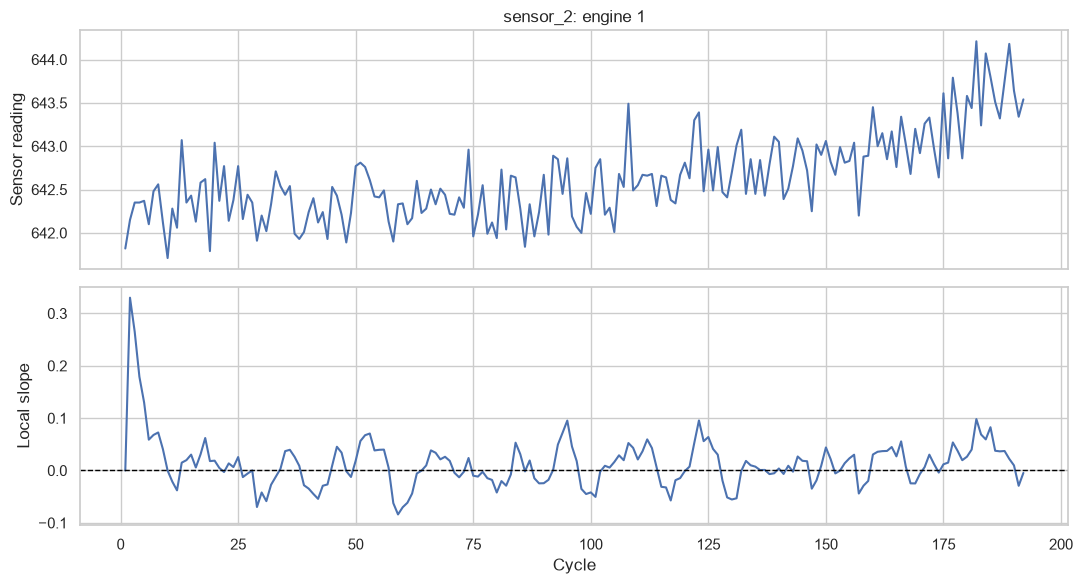

In [5]:
sensor = "sensor_2"
engine = train_features.loc[train_features.unit == train_features.unit.min()]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(engine.cycle, engine[sensor])
axes[0].set(title=f"{sensor}: engine 1", ylabel="Sensor reading")
axes[1].plot(engine.cycle, engine[f"{sensor}_slope"])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Cycle", ylabel="Local slope")
plt.tight_layout()
plt.show()


**Next:** `04_model_training.ipynb`. The API uses this same feature function and the window saved in the model manifest.
